# Classificador Vizinho Mais Próximo (1-NN)

*Implementação com scikit-learn · base original (sem pré-processamento)*

Cada amostra de teste recebe a classe da amostra de treino mais próxima segundo a distância de Minkowski de ordem $m$:

$$d_m(\mathbf{x}, \mathbf{z}) = \Big(\sum_{k} |x_k - z_k|^m\Big)^{1/m}, \qquad m \in \{1/2,\ 2/3,\ 1,\ 3/2,\ 2,\ 5/2\}$$

Para $m < 1$, $d_m$ não satisfaz a desigualdade triangular (não é métrica), mas continua definindo um critério de proximidade.

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=False)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5456 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
import warnings
from sklearn.neighbors import KNeighborsClassifier

# para m < 1 o scikit-learn avisa que a distância não é métrica e usa busca por força bruta
warnings.filterwarnings("ignore", message="Mind that for 0 < p < 1")

ORDENS = {"1/2": 1/2, "2/3": 2/3, "1": 1, "3/2": 3/2, "2": 2, "5/2": 5/2}
MODELOS = {f"m = {nome}": KNeighborsClassifier(n_neighbors=1, p=m, algorithm="brute") for nome, m in ORDENS.items()}

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification_sklearn_raw", "vizinho_mais_prox")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

média  desvio  máxima  mínima  mediana  t_treino_ms  \
split modelo                                                          
20/80 m = 1/2  0.9462  0.0038  0.9544  0.9356   0.9462       1.4460   
      m = 2/3  0.9467  0.0042  0.9565  0.9359   0.9468       1.4177   
      m = 1    0.9471  0.0042  0.9567  0.9347   0.9471       1.3294   
      m = 3/2  0.9462  0.0044  0.9562  0.9299   0.9463       1.2852   
      m = 2    0.9448  0.0043  0.9553  0.9301   0.9448       1.3123   
      m = 5/2  0.9440  0.0044  0.9544  0.9278   0.9442       1.3611   
30/70 m = 1/2  0.9560  0.0037  0.9665  0.9450   0.9561       1.3954   
      m = 2/3  0.9564  0.0038  0.9660  0.9445   0.9563       1.3397   
      m = 1    0.9569  0.0039  0.9657  0.9442   0.9564       1.3311   
      m = 3/2  0.9562  0.0039  0.9636  0.9429   0.9560       1.2560   
      m = 2    0.9551  0.0037  0.9620  0.9413   0.9550       1.3137   
      m = 5/2  0.9542  0.0037  0.9618  0.9421   0.9542       1.3382   
50/50 m = 1/2  0.9653  0.0036  0.9758  0.9571   0.9650       1.4096   
      m = 2/3  0.9654  0.0033  0.9751  0.9571   0.9648       1.4415   
      m = 1    0.9658  0.0033  0.9743  0.9568   0.9656       1.4037   
      m = 3/2  0.9656  0.0035  0.9747  0.9582   0.9652       1.3696   
      m = 2    0.9649  0.0035  0.9740  0.9586   0.9645       1.3996   
      m = 5/2  0.9643  0.0035  0.9733  0.9568   0.9641       1.3744   
70/30 m = 1/2  0.9701  0.0037  0.9780  0.9578   0.9704       1.4359   
      m = 2/3  0.9704  0.0038  0.9798  0.9609   0.9700       1.4861   
      m = 1    0.9708  0.0038  0.9804  0.9615   0.9707       1.4595   
      m = 3/2  0.9707  0.0039  0.9792  0.9621   0.9707       1.4072   
      m = 2    0.9700  0.0039  0.9798  0.9609   0.9700       1.4449   
      m = 5/2  0.9694  0.0039  0.9786  0.9615   0.9694       1.4684   
80/20 m = 1/2  0.9710  0.0044  0.9817  0.9624   0.9711       2.6336   
      m = 2/3  0.9717  0.0044  0.9835  0.9615   0.9716       2.6890   
      m = 1    0.9716  0.0045  0.9835  0.9597   0.9716       2.5152   
      m = 3/2  0.9716  0.0045  0.9844  0.9569   0.9716       2.6152   
      m = 2    0.9711  0.0049  0.9844  0.9578   0.9707       2.5690   
      m = 5/2  0.9704  0.0050  0.9817  0.9578   0.9707       2.6748   

               t_teste_ms  
split modelo               
20/80 m = 1/2    115.6836  
      m = 2/3    115.2766  
      m = 1       12.9588  
      m = 3/2    115.8453  
      m = 2        8.0686  
      m = 5/2    115.3345  
30/70 m = 1/2    120.1673  
      m = 2/3    119.1553  
      m = 1       14.0853  
      m = 3/2    118.9841  
      m = 2        8.5077  
      m = 5/2    120.4917  
50/50 m = 1/2    187.6737  
      m = 2/3    186.6403  
      m = 1       20.2529  
      m = 3/2    186.7061  
      m = 2       11.1079  
      m = 5/2    186.8703  
70/30 m = 1/2    130.8130  
      m = 2/3    131.6176  
      m = 1       15.1173  
      m = 3/2    131.7135  
      m = 2       11.6122  
      m = 5/2    132.5061  
80/20 m = 1/2    257.1291  
      m = 2/3    256.7358  
      m = 1       27.9611  
      m = 3/2    256.2276  
      m = 2       22.4299  
      m = 5/2    257.7099

## OBS 2 — Matrizes de confusão da melhor e da pior rodada

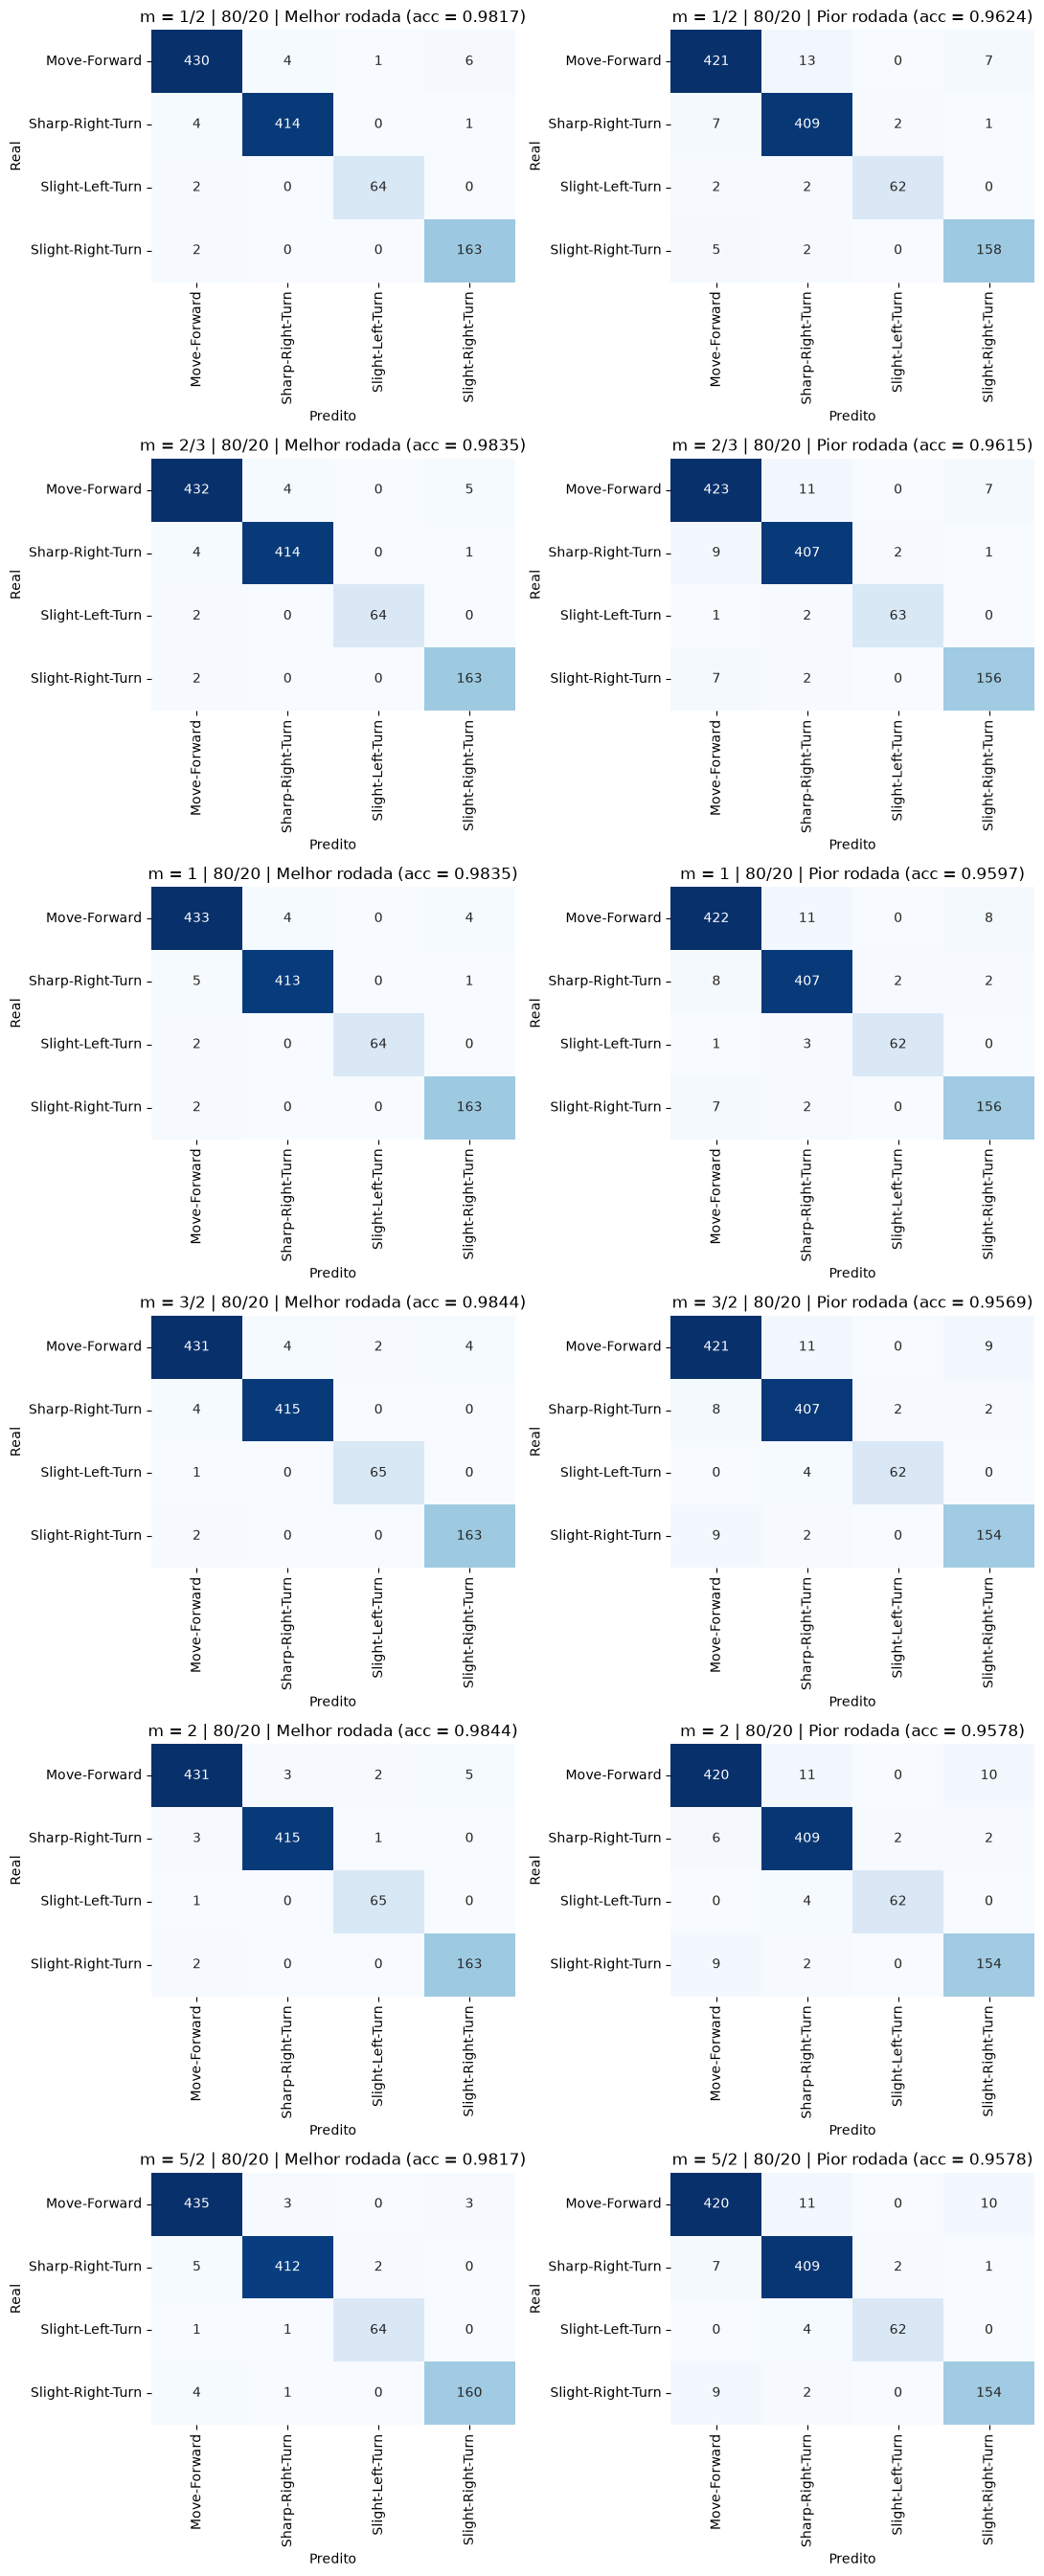

In [5]:
matrizes_confusao(res, confusoes, classes, splits=["80/20"])

## OBS 3 — Efeito da separação treino/teste

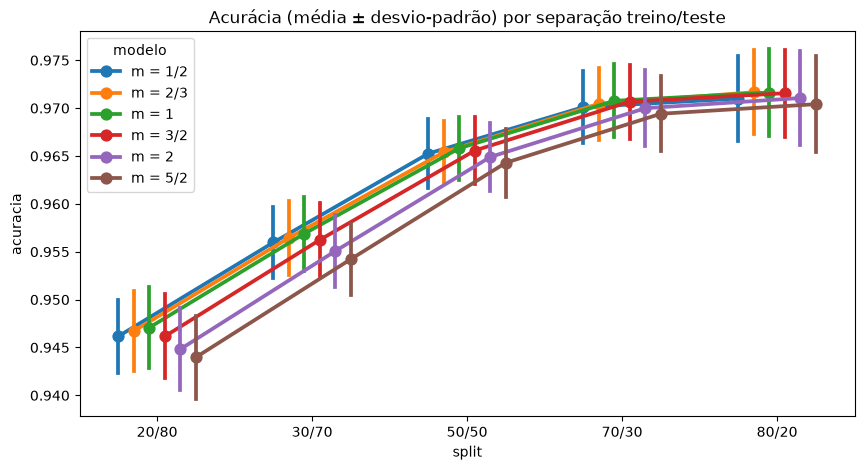

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  mediana
classe            split modelo                                          
Move-Forward      20/80 m = 1/2  0.9379  0.0083  0.9632  0.9138   0.9388
                        m = 2/3  0.9391  0.0085  0.9649  0.9138   0.9399
                        m = 1    0.9405  0.0085  0.9603  0.9178   0.9410
                        m = 3/2  0.9406  0.0086  0.9563  0.9104   0.9413
                        m = 2    0.9398  0.0086  0.9558  0.9133   0.9405
                        m = 5/2  0.9395  0.0085  0.9569  0.9116   0.9399
                  30/70 m = 1/2  0.9494  0.0068  0.9669  0.9274   0.9488
                        m = 2/3  0.9507  0.0071  0.9644  0.9261   0.9507
                        m = 1    0.9521  0.0071  0.9695  0.9248   0.9520
                        m = 3/2  0.9515  0.0070  0.9669  0.9242   0.9507
                        m = 2    0.9505  0.0068  0.9657  0.9209   0.9494
                        m = 5/2  0.9494  0.0067  0.9624  0.9222   0.9488
                  50/50 m = 1/2  0.9597  0.0071  0.9737  0.9393   0.9601
                        m = 2/3  0.9613  0.0070  0.9764  0.9447   0.9610
                        m = 1    0.9627  0.0068  0.9782  0.9456   0.9628
                        m = 3/2  0.9622  0.0070  0.9782  0.9438   0.9628
                        m = 2    0.9610  0.0068  0.9764  0.9465   0.9601
                        m = 5/2  0.9601  0.0068  0.9773  0.9465   0.9592
                  70/30 m = 1/2  0.9654  0.0073  0.9788  0.9395   0.9667
                        m = 2/3  0.9682  0.0072  0.9834  0.9470   0.9697
                        m = 1    0.9695  0.0071  0.9849  0.9501   0.9697
                        m = 3/2  0.9687  0.0072  0.9849  0.9501   0.9690
                        m = 2    0.9676  0.0071  0.9818  0.9486   0.9682
                        m = 5/2  0.9662  0.0071  0.9788  0.9455   0.9675
                  80/20 m = 1/2  0.9653  0.0088  0.9841  0.9478   0.9660
                        m = 2/3  0.9690  0.0084  0.9864  0.9478   0.9683
                        m = 1    0.9696  0.0082  0.9841  0.9524   0.9683
                        m = 3/2  0.9690  0.0083  0.9864  0.9478   0.9683
                        m = 2    0.9682  0.0083  0.9864  0.9478   0.9683
                        m = 5/2  0.9669  0.0085  0.9864  0.9456   0.9660
Sharp-Right-Turn  20/80 m = 1/2  0.9667  0.0071  0.9815  0.9464   0.9672
                        m = 2/3  0.9681  0.0074  0.9821  0.9440   0.9696
                        m = 1    0.9693  0.0072  0.9851  0.9482   0.9708
                        m = 3/2  0.9676  0.0074  0.9839  0.9470   0.9678
                        m = 2    0.9667  0.0072  0.9827  0.9476   0.9675
                        m = 5/2  0.9658  0.0074  0.9821  0.9458   0.9666
                  30/70 m = 1/2  0.9725  0.0052  0.9877  0.9598   0.9724
                        m = 2/3  0.9738  0.0052  0.9905  0.9605   0.9741
                        m = 1    0.9751  0.0054  0.9905  0.9625   0.9751
                        m = 3/2  0.9744  0.0057  0.9871  0.9578   0.9748
                        m = 2    0.9738  0.0059  0.9891  0.9584   0.9734
                        m = 5/2  0.9733  0.0061  0.9898  0.9584   0.9734
                  50/50 m = 1/2  0.9778  0.0050  0.9886  0.9628   0.9781
                        m = 2/3  0.9777  0.0050  0.9886  0.9619   0.9781
                        m = 1    0.9784  0.0048  0.9905  0.9647   0.9781
                        m = 3/2  0.9784  0.0049  0.9886  0.9647   0.9786
                        m = 2    0.9785  0.0051  0.9895  0.9638   0.9790
                        m = 5/2  0.9783  0.0051  0.9886  0.9647   0.9781
                  70/30 m = 1/2  0.9814  0.0055  0.9936  0.9666   0.9809
                        m = 2/3  0.9808  0.0053  0.9936  0.9682   0.9809
                        m = 1    0.9809  0.0050  0.9952  0.9698   0.9809
                        m = 3/2  0.9813  0.0047  0.9936  0.9714   0.9809
                        m = 2    0.9810  0.0050  0.9952  0.9698   0.9809
                   

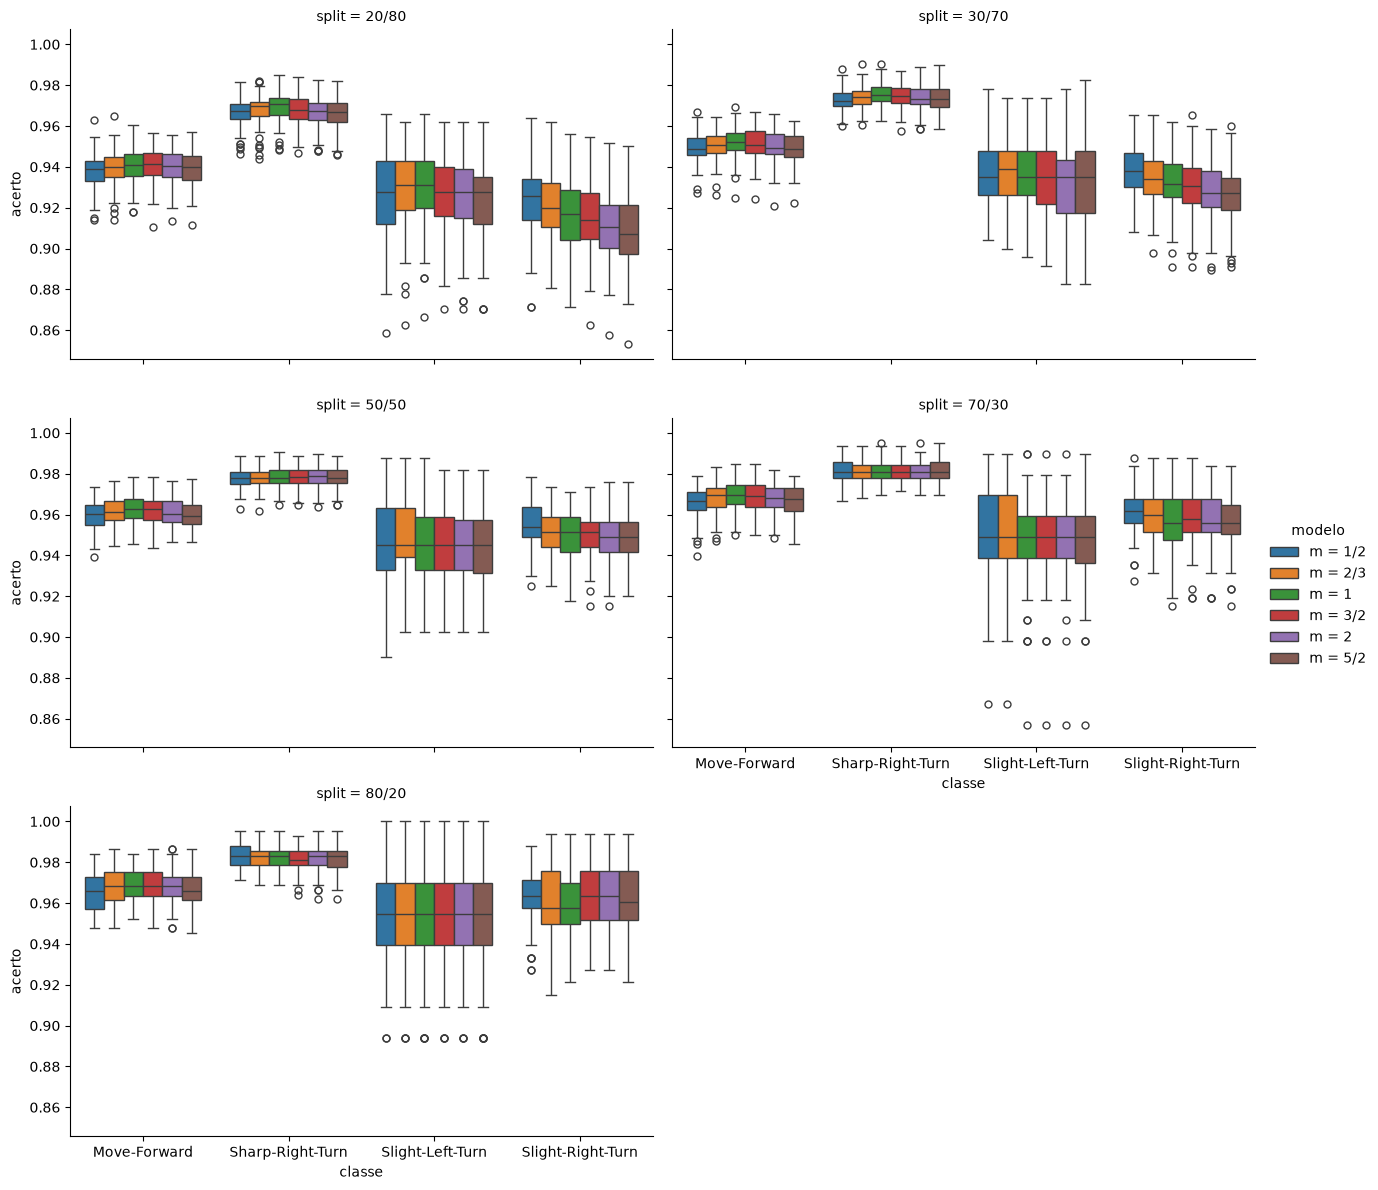

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: m = 2/3 com split 80/20 -> acurácia média 0.9717

Tempo médio por rodada (ms):
  m = 1/2: treino 1.664 | teste 162.293
  m = 2/3: treino 1.675 | teste 161.885
  m = 1: treino 1.608 | teste 18.075
  m = 3/2: treino 1.587 | teste 161.895
  m = 2: treino 1.608 | teste 12.345
  m = 5/2: treino 1.643 | teste 162.583

Efeito do split (acurácia média 20/80 -> 80/20):
  m = 1/2: 0.9462 -> 0.9710 (+0.0248)
  m = 2/3: 0.9467 -> 0.9717 (+0.0249)
  m = 1: 0.9471 -> 0.9716 (+0.0245)
  m = 3/2: 0.9462 -> 0.9716 (+0.0254)
  m = 2: 0.9448 -> 0.9711 (+0.0262)
  m = 5/2: 0.9440 -> 0.9704 (+0.0264)

Taxa de acerto média por classe (todas as rodadas):
  Slight-Left-Turn: 0.9413
  Slight-Right-Turn: 0.9434
  Move-Forward: 0.9574
  Sharp-Right-Turn: 0.9765
Classe mais fácil: Sharp-Right-Turn | mais difícil: Slight-Left-Turn
